# CS5 - Saturation-Model Selection & Sensitivity (well 30/6-5)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/case_studies/cs5_saturation_model_sensitivity_30_6-5.ipynb)

**Petrophys Case Studies - a decision-focused project lesson**

## Part 1 - The brief

> **"Which water-saturation model should we trust in this shaly sand, and how much
> does the choice move net pay and hydrocarbon pore volume (HCPV)? Quantify the
> sensitivity of the answer to both the *model* and the *parameter* assumptions."**

A subsurface team has a shaly-sand reservoir on the North Sea well **30/6-5**. The
gross rock volume is fixed by seismic; the volumetric uncertainty that the team
controls comes almost entirely from the **petrophysical water saturation (Sw)**. In a
*clean* sand Archie's equation is sufficient, but this interval carries clay,
and clay adds an extra conductive path that Archie does **not** account for - so Archie
reads Sw too high and undercounts pay. Several shaly-sand corrections exist
(Simandoux, Indonesia, and the regional North Sea and Nigeria forms - plus the
lab-data Waxman-Smits / Dual-Water family when CEC and SCAL exist) and they
disagree.

The deliverable of this lesson is **not** a single number. It is:

1. A **decision table** - the five Sw models side by side, each with net pay, Sw averaged over
   the pay, and a hydrocarbon-pore-thickness index (`HCPV`, metres of hydrocarbon-filled pore
   column).
2. A **sensitivity / tornado analysis** - how much net pay and HCPV move when we sweep
   the key uncertain inputs (Rw, m, n, Vcl cutoff).
3. A **reasoned recommendation** - which model to trust here and why, with an
   **uncertainty band** on HCPV implied by the sensitivity.

This case study reuses the fundamentals taught in tutorial 07 (saturation) but is
oriented toward a *decision under uncertainty*, not toward teaching the equations.

**What you will learn**

- How to run several saturation models on one interval with a common parameter set
  (`pp.interpret` with `sw_model=`).
- How to turn model differences into a decision table of net pay and HCPV.
- How to build a one-at-a-time sensitivity (tornado) and read which assumption to measure first.
- How to quote an uncertainty band instead of a single number.

**Prerequisites.** Lesson 07 (water saturation models), lesson 09 (net pay; it also reconciles
this well's Rw) and case study CS1 (the full evaluation of the same well). The base install is
enough.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Part 2 - The well & the data

**Well 30/6-5** is a North Sea clastic well of the GeoLink dataset (depths in metres). It
penetrates two sand packages relevant to us:

| Interval | Depth (m) | Fluid | Role in this study |
|---|---|---|---|
| Brent Group sands (`BRENT GP.` in the bundled tops) | 2841 - 2958 | hydrocarbon-bearing | **the reservoir** we evaluate |
| Statfjord sands | 3223 - 3556 | water leg | **Pickett check** of the Archie parameters (Sw~1; the regression still fails, and 4.2 shows why) |

The two-interval design is deliberate: a Pickett plot can only pin down the Archie
parameters (m, and via the intercept Rw) from a **water-bearing** zone where Sw is known
to be ~1. The deeper Statfjord water leg is that zone. The water-leg premise is solid here -
CS1's formation roll-up finds only scattered, low net-to-gross pay flags in the Statfjord and
does not treat it as a target, and the NPD records no discovery there - but section 4.2 shows
that a Pickett *regression* fails on this leg anyway, for reasons worth understanding.

**What we have:** GR, RHOB, NPHI, deep resistivity (RDEP), plus core (PHIC, SWC).
**What we are missing:** no Rw measurement of our own (the header Rw comes from Statoil's 1981
evaluation; 4.1 discusses it), no CEC/Qv lab data, no independent m/n from SCAL.
Every one of those becomes an *assumption* that we flag and then stress-test in the
sensitivity analysis - which is exactly the point of the brief.

A scope call on the core, stated explicitly rather than quietly dropped: the well carries
core water saturations (SWC) inside the evaluated reservoir (counted below, in v/v). They exist,
they sit in the interval, and a production study would benchmark the five Sw models against
them - with the standard caveat that core saturations from non-preserved core are altered by
mud-filtrate flushing and fluid loss during recovery. This study stays **log-only** by scope,
so the core saturations are acknowledged, not used.

In [2]:
import warnings

import pandas as pd
import petrophys as pp
from petrophys.interpretation.core_analysis import core_data

# SWC and SOC are stored in percent though labelled 'frac' (CS1 explains); hide only that message.
warnings.filterwarnings("ignore", message="(SWC|SOC): inferred percent core saturation")
pd.set_option("display.precision", 3)

well = pp.read(pp.sample("30_6-5"))
core_data(well, top=2841, bottom=2958).to_dataframe()["CSW"].describe()

count    74.000
mean      0.482
std       0.159
min       0.137
25%       0.365
50%       0.474
75%       0.601
max       0.846
Name: CSW, dtype: float64

There are 74 core Sw points in the Brent Group, from 0.14 to 0.85 v/v.

## Part 3 - Workflow plan

The study is a set of `pp.interpret` runs that differ in one thing at a time:

1. **Base parameters** - the operator's documented Rw, a, m and n, and the clastic cutoffs.
2. **Five runs, one per Sw model** (`sw_model=`). Clay volume, porosity, Rw and the cutoffs are
   computed the same way in every run; only the saturation equation changes.
3. **Pickett check on the water leg** - an illustrative *m* and Rw from the Statfjord. The log-only
   Pickett is poorly constrained here, which is why the base case rests on the operator's
   documented constants - a realistic petrophysical decision.
4. **Decision table** - net pay, average Sw and HCPV per model over the Brent Group, from
   `zone_summary()`.
5. **Parameter sensitivity** - sweep Rw, m, n and the Vcl cutoff one at a time; build a tornado.
6. **Recommendation** - pick a model, quote an HCPV uncertainty band.

CS1 interprets the same well with the workflow's auto-routed saturation model; here every run
names its model. CS1 also leaves a, m and n to the workflow's lithology defaults and assumes a 50 degF
surface temperature, so its Brent Group net pay (24.4 m) is not the 26.1 m of the Archie run here; with
this study's constants and the default surface temperature the auto-routed run gives 26.1 m too.

## Part 4 - Execution

### 4.1 Base parameters (documented, not guessed)

The LAS header carries the operator's parameter block: **Rw = 0.070 ohm.m at RWT = 230 degF**
(reservoir temperature, Statoil's 1981 evaluation). Lesson 09 cross-checks it against the completion-report
evaluation, which used the same Rw with **a = 0.80, m = n = 2** - constants that reproduce their
zone-by-zone pay table and bracket the NPD's 2907 m OWC (case study 1). We adopt that set as the
base case, with the clastic cutoffs (`Vcl < 0.40`, `PHIE > 0.08`, `Sw < 0.60`) for every sample.
The Rw is given with its temperature, so each run corrects it along the temperature profile.

The zone named in `zones=` changes no setting; it names the Brent Group interval so that
`result.zone_summary()` reports it. Documented is not the same as certain - the vintage of the
evaluation, the fact that the Rw is not our own measurement and the absence of SCAL all leave real
uncertainty, which is exactly what the tornado in Part 6 sweeps.

Model families and what each one is *for*:

| Model | Clay term | When you reach for it |
|---|---|---|
| **Archie** | none | clean sand baseline (biased high in shaly rock) |
| **Simandoux** | `Vcl/Rcl` (linear) | classic shaly-sand, dispersed clay |
| **Indonesia** (Poupon-Leveaux) | `Vcl^(1-Vcl/2)/sqrt(Rcl)` | laminated/dispersed, high-Vcl robust |
| **North Sea** (regional) | `Vsh^1.6/Rtsh` laminated term | North Sea shaly sands - the local convention for this well |
| **Nigeria-type** (regional) | `Vcl^c` term in sqrt space | Niger-delta-style laminated sands |

All five run on effective porosity with the clay handled by an explicit Vcl term, and take the
clay resistivity the workflow measures in the well's shales (Rcl, the median deep resistivity of
the shale samples; the `saturation` step records it). The total-porosity, lab-data family
(Waxman-Smits, Dual-Water) needs CEC / Rwb measurements this well does not have, so it is
**excluded rather than guessed** - lesson 07 (section 4) explains why, and the workflow behaves
the same way: it runs Waxman-Smits only when `cec` and `b_coeff` are supplied, and Dual Water only
with a supplied `rwb`; it never estimates them.

In [3]:
BRENT = [{"zone": "Brent Group", "top": 2841, "bottom": 2958}]
BASE = dict(rw=0.07, rw_meas_temp="230 degF", a=0.8, m=2.0, n=2.0,       # operator's evaluation
            vcl_cutoff=0.40, phie_cutoff=0.08, sw_cutoff=0.60,      # clastic standards
            zones=BRENT)
MODELS = ["archie", "simandoux", "indonesia", "north_sea", "nigeria_schlumberger"]
runs = {model: pp.interpret(well, sw_model=model, **BASE) for model in MODELS}

### 4.2 Pickett check on the water leg

The Pickett plot is `log(Rt)` against `log(PHI)` for water-bearing points: the slope gives `-m`
and the intercept `log(a*Rw)`. The plot below draws the cleaner Statfjord samples (Vcl up to
0.30) with the base-case lines (a = 0.8, m = n = 2 and the base Rw at Statfjord temperature, the
median of the run's `RW` curve over the plotted points); `pickett_analysis` then fits the same
points by regression.
It fits *m* and the intercept with a = 1; *n* comes from SCAL, which we do not have.

[repository]\src\petrophys\visualization\style.py:102: DataQualityWarning: Pickett input: 41 of 22176 value(s) require porosity in (0,1] and finite positive resistivity (zero-based flat indices [20786, 20974, 20975, 20976, 20979]). Invalid points are omitted from this plot.
  return _label_short_log_axes(function(*args, **kwargs))


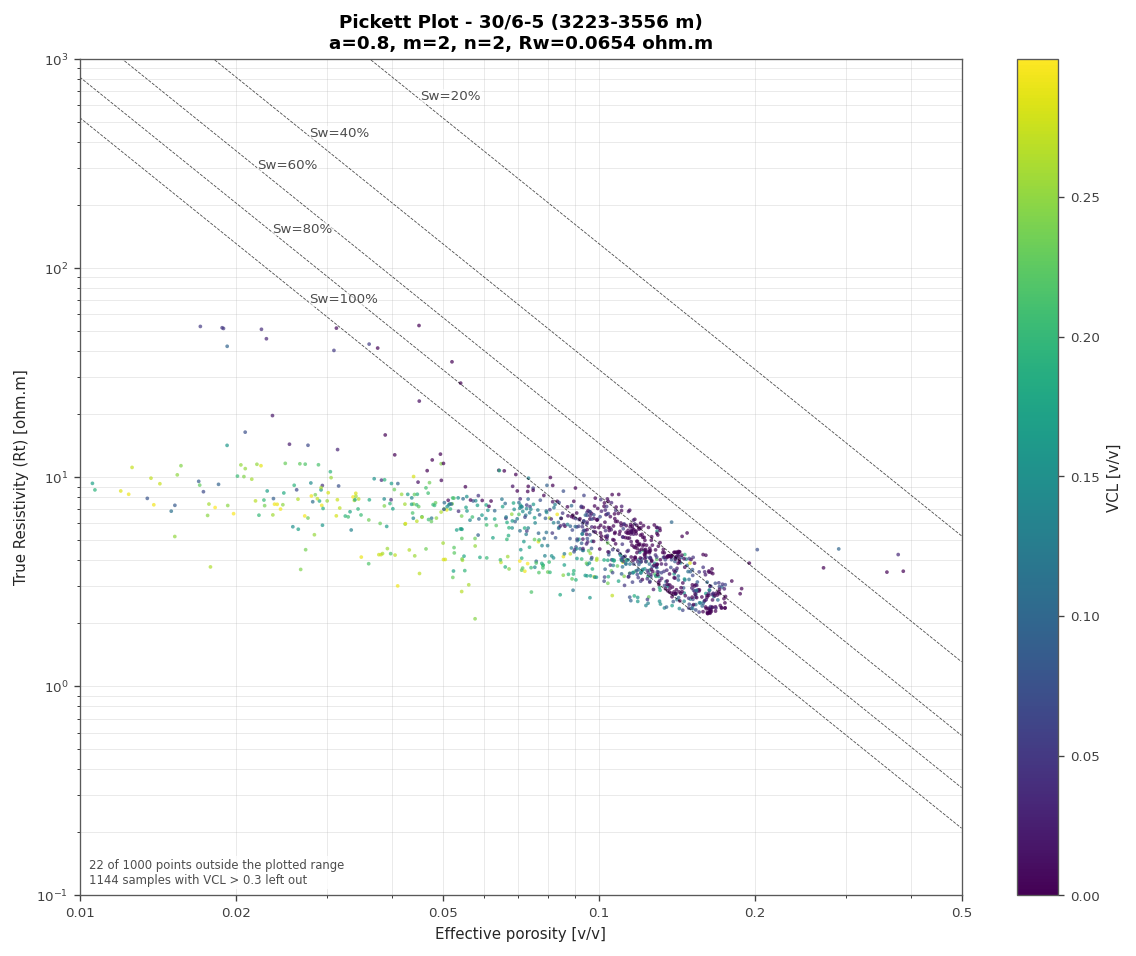

[temporary directory]\ipykernel_18932\2980182672.py:5: UserWarning: Pickett fit gives m = 0.81, outside the usual 1.3-3 range: the samples are probably not all clean and water-bearing (Sw = 1). Fit the water leg only, or read m from the lower envelope of the points.
  pickett_analysis(water["RDEP"].data, water["PHIE"].data, vcl=water["VCL"].data, vcl_cutoff=0.30)[1]


{'m': 0.8080444381750765,
 'slope': -0.8080444381750765,
 'intercept': -0.16660876274968506,
 'rw': 0.6813829108969476,
 'method': 'rma',
 'r_squared': 0.4801969639203325,
 'p_value': 7.856968250123597e-141,
 'std_err': 0.018628814744084347,
 'n_points': 978}

In [4]:
from petrophys.interpretation.electrical.cementation import pickett_analysis

pp.crossplot(runs["archie"], "PHIE", "RDEP", top=3223, bottom=3556, a=0.8, vcl_max=0.30).show()
water = runs["archie"].well.depth_slice(3223, 3556)          # the Statfjord water leg
pickett_analysis(water["RDEP"].data, water["PHIE"].data, vcl=water["VCL"].data, vcl_cutoff=0.30)[1]

The clean, porous samples (dark) fall mostly between the Sw = 80% and 100% lines, a fifth of them
just below the water line: the base-case constants
read the water leg as wet, as they should. The regression tells a different story.

**The fit is not usable.** An *m* of 0.81 is far below the physical 1.6-2.1 range, the
R-squared is only 0.48, and the apparent Rw (a = 1) is 0.68 ohm.m - against a base
Rw near 0.065 ohm.m at this depth. That combination is not just noise - it is the signature of
regressing through a *mixed* cloud. Deep resistivity changes little across the leg's porosity
range, so the low-porosity (tight or shaly) samples read far less resistive than Archie with
m = 2 predicts and the most porous ones more resistive; scatter in porosity flattens a regression
slope further, and a flatter slope lifts the intercept. Lesson 07 dissects exactly this trap on
the same interval and shows the industry alternative: fix m at a plausible value and pick Rw from
the **lower envelope** of the clean cloud - which lands close to the operator's value. The
regression is discarded, and the base case stays on the operator's documented constants.

### 4.3 The decision table: five models over the Brent Group

`zone_summary()` rolls each run up over the Brent Group: net pay, pay / gross, and PHIE, Sw and
VCL averaged over the net-pay samples, plus HCPV, the hydrocarbon-pore-thickness index of the brief
(metres of hydrocarbon-filled pore column). Multiplied by area it becomes HCPV proper; because the area is
common to all models, the index carries the full model sensitivity of the volumetric answer.

In [5]:
decision = pd.concat({model: run.zone_summary() for model, run in runs.items()}).droplevel(1)
decision[["Net Pay (m)", "Pay/Gross", "Avg PHIE", "Avg Sw", "Avg VCL", "HCPV"]]

,Net Pay (m),Pay/Gross,Avg PHIE,Avg Sw,Avg VCL,HCPV
archie,26.060,0.223,0.211,0.289,0.060,3.908
simandoux,30.175,0.258,0.202,0.302,0.083,4.251
indonesia,30.785,0.263,0.201,0.301,0.085,4.322
north_sea,28.346,0.242,0.205,0.291,0.077,4.128
nigeria_schlumberger,29.108,0.249,0.204,0.297,0.080,4.180


Archie books the least pay (26.1 m, HCPV 3.91 m); the four shaly-sand models book
28.3-30.8 m with HCPV 4.13-4.32 m, Indonesia the most.
That ordering is the expected effect of unmodelled clay conductivity: Archie attributes the
clay's conduction to water, reads Sw too high in shaly sand and undercounts pay. The pay averages
move little (average Sw 0.29-0.30 over the pay), because a shaly-sand model mostly adds *marginal* samples that sit just
under the Sw cutoff.

## Part 5 - Integrated result

### 5.1 Figure - the five Sw curves over the Brent Group

`pp.plot` with `curves=` draws several wells or results in one figure, a track per curve. Given a
mapping of runs, it labels each line with its key - here the model.

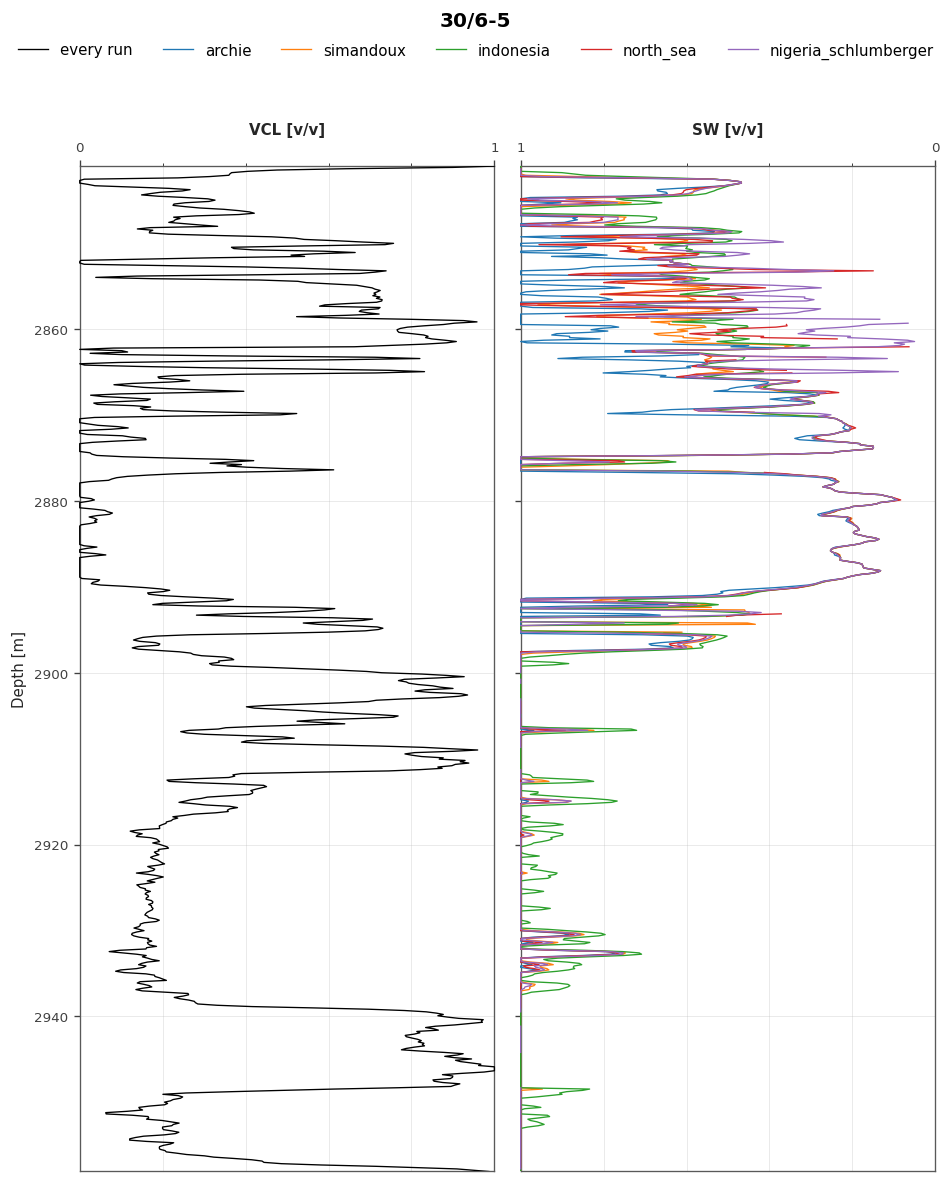

In [6]:
pp.plot(runs, curves=["VCL", "SW"], top=2841, bottom=2958, figsize=(8, 10)).show()

#### Reading the saturation track

The VCL curves of the five runs coincide (only the Sw equation differs). The Sw scale runs from 1
on the left to 0 on the right. In the clean Etive sand (about 2876-2890 m) all five models agree.
Wherever VCL is raised in rock that keeps some porosity they part: Archie reads the wettest and the
separation grows with Vcl. That is the clay-conductivity effect again. The shaly beds below 2900 m
have no effective porosity, so every model reads Sw = 1 there.

One warning sign sits in the Ness Fm. shales (about 2855-2865 m, VCL 0.6-0.9): there the
Nigeria-type form returns Sw as low as 0.05 - a shale reading as hydrocarbon - and the North Sea
form has gaps where it finds no solution. Both over-correct for clay conductivity with the shale
resistivity of this well. The Vcl cutoff keeps those samples out of the pay, so the decision table
is not affected, but neither regional form should be trusted in the shales.

### 5.2 Figure - net pay and HCPV by model (the decision bar chart)

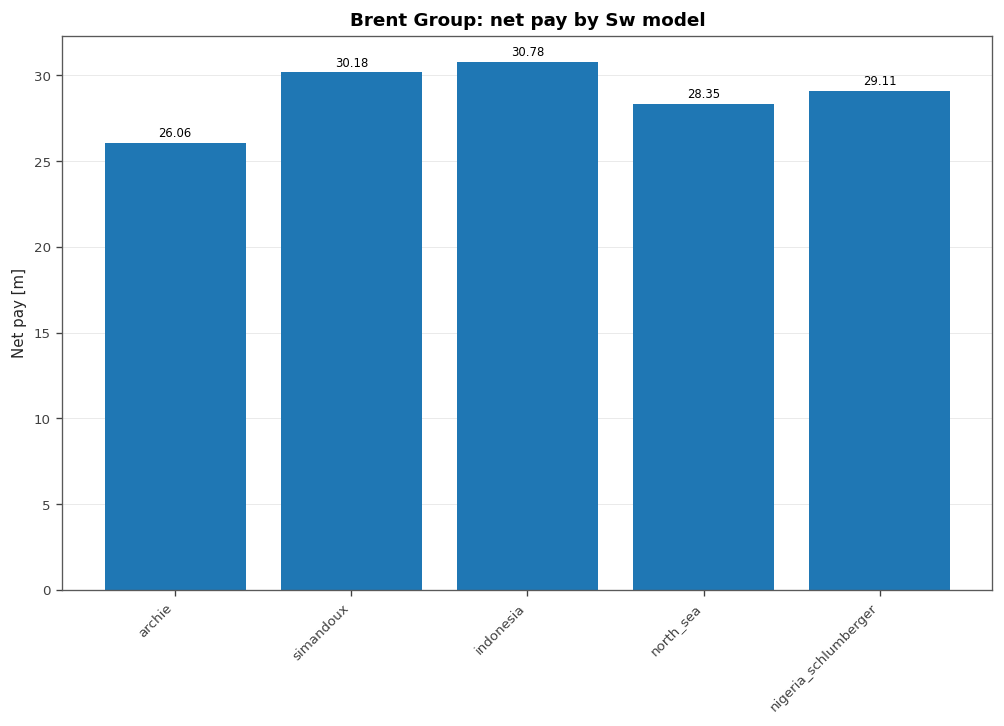

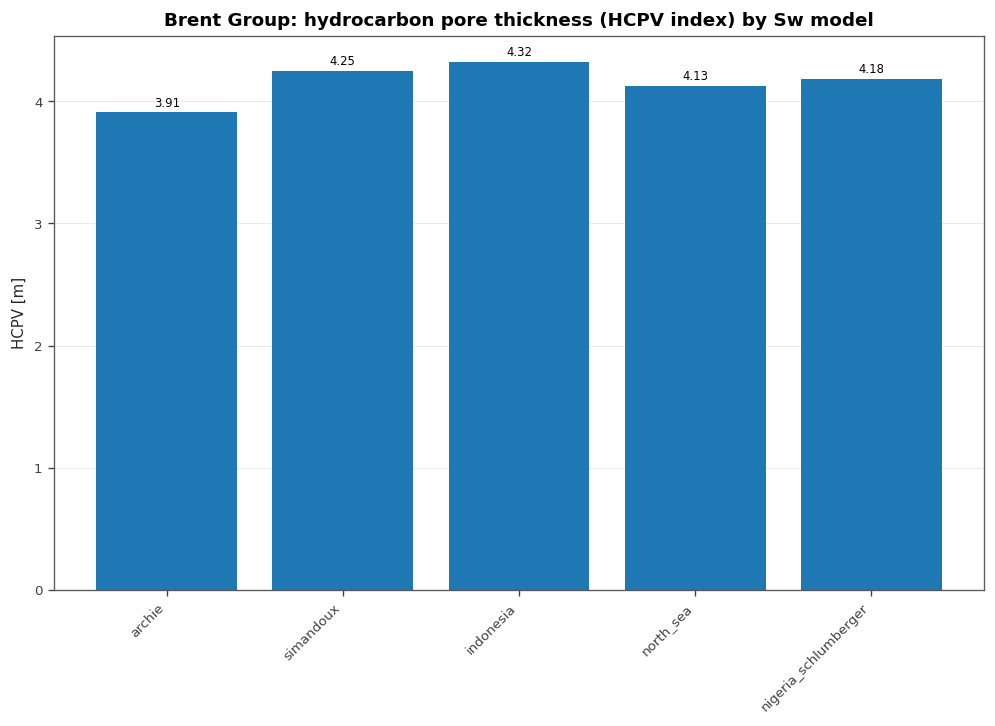

In [7]:
pp.bar_chart(MODELS, decision["Net Pay (m)"], value_labels=True, ylabel="Net pay [m]",
             title="Brent Group: net pay by Sw model").show()
pp.bar_chart(MODELS, decision["HCPV"], value_labels=True, ylabel="HCPV [m]",
             title="Brent Group: hydrocarbon pore thickness (HCPV index) by Sw model").show()

The model choice alone moves net pay by 4.7 m and HCPV by 0.41 m
(about 10% of the Indonesia HCPV) - almost all of it the step from Archie to any
shaly-sand model.

## Part 6 - Parameter sensitivity (the tornado)

The decision table captured **model** uncertainty. Now we quantify **parameter** uncertainty for a
single reference model. We use **Indonesia** as the reference - the robust workhorse for dispersed
shaly sands, and the model recommended in Part 7 - and sweep each key input across a defensible
low/high range while holding the others at base:

| Assumption | Low | Base | High | Why uncertain |
|---|---|---|---|---|
| Rw (ohm.m at 230 degF) | 0.05 | 0.070 | 0.09 | Statoil's value, not our own measurement; 1981 vintage |
| m | 1.8 | 2.0 | 2.2 | operator value, but no SCAL of our own |
| n | 1.8 | 2.0 | 2.2 | no SCAL |
| Vcl cutoff | 0.30 | 0.40 | 0.50 | pay-flag choice (standard = 0.40) |

`parameter_sensitivity` (in `petrophys.evaluation`) does the bookkeeping: it calls an evaluation
once at base and twice per assumption, and returns one row per assumption and output with `low`,
`base`, `high` and `swing` (|high - low|), widest swing first. The evaluation is one
`pp.interpret` run summarized over the Brent Group.

In [8]:
from petrophys.evaluation import parameter_sensitivity

def brent(sw_model="indonesia", **changes):
    """The Brent Group summary of one run: base settings with some of them changed."""
    return pp.interpret(well, **{**BASE, "sw_model": sw_model, **changes}).zone_summary().iloc[0]

sens = parameter_sensitivity(brent, {
    "Rw 0.05 / 0.09": ({"rw": 0.05}, {"rw": 0.09}),
    "m 1.8 / 2.2": ({"m": 1.8}, {"m": 2.2}),
    "n 1.8 / 2.2": ({"n": 1.8}, {"n": 2.2}),
    "Vcl cutoff 0.30 / 0.50": ({"vcl_cutoff": 0.30}, {"vcl_cutoff": 0.50}),
}, outputs=["Net Pay (m)", "HCPV"])
sens[["output", "case", "low", "base", "high", "swing"]]

,output,case,low,base,high,swing
0,Net Pay (m),m 1.8 / 2.2,33.376,30.785,25.755,7.620
1,Net Pay (m),Rw 0.05 / 0.09,32.461,30.785,27.584,4.877
2,Net Pay (m),Vcl cutoff 0.30 / 0.50,29.718,30.785,31.242,1.524
3,Net Pay (m),n 1.8 / 2.2,31.242,30.785,30.328,0.914
4,HCPV,m 1.8 / 2.2,4.723,4.322,3.723,1.000
5,HCPV,Rw 0.05 / 0.09,4.683,4.322,3.894,0.789
6,HCPV,n 1.8 / 2.2,4.559,4.322,4.098,0.461
7,HCPV,Vcl cutoff 0.30 / 0.50,4.240,4.322,4.352,0.111


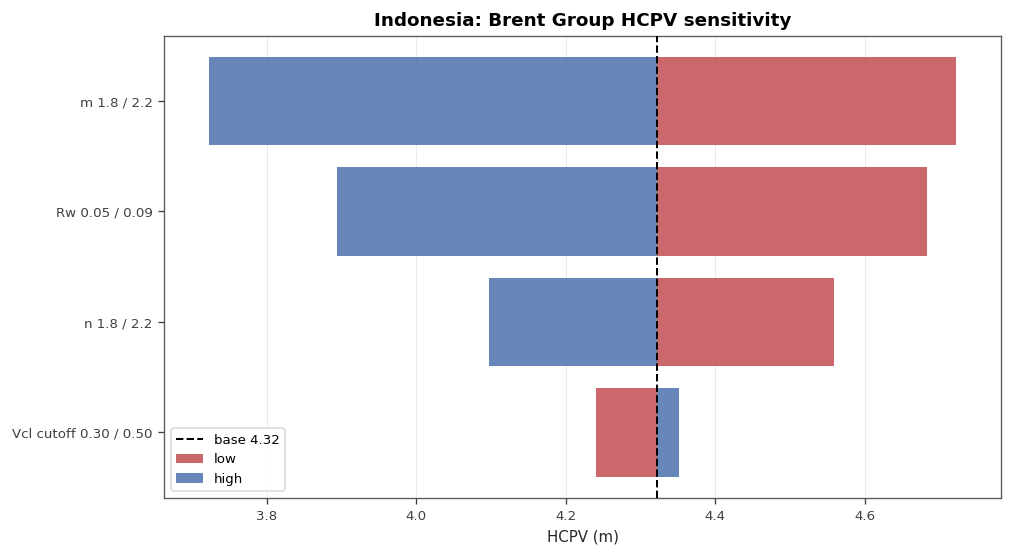

In [9]:
hcpv = sens[sens["output"] == "HCPV"]
pp.tornado_plot(hcpv["case"], hcpv["low"], hcpv["high"], base=hcpv["base"].iloc[0],
                xlabel="HCPV (m)", title="Indonesia: Brent Group HCPV sensitivity");

#### Highest-value measurement

The widest bar is where a measurement buys the most certainty. Here it is **m**, followed
by **Rw** (HCPV swings of 1.00 m and 0.79 m), then n (0.46 m) and the
Vcl cutoff (0.11 m). The fix differs by lever: SCAL formation-factor tests on core plugs pin
down *m*, resistivity-index tests pin down *n*, a produced- or formation-water sample pins down Rw,
and core or test data calibrate the clay cutoff. Note how close the leading bars are - a small
change in the sweep ranges could reorder them, so budget for the top two rather than only the
first. On net pay the order is the same at the top, but the Vcl cutoff moves ahead of n.

### 6.1 Combining model + parameter uncertainty into an HCPV band

To quote an honest range we combine both sources:

- **Low case**: the most pessimistic *model* (Archie) at its most pessimistic parameter
  corner.
- **High case**: the recommended model (Indonesia) at its most optimistic parameter
  corner - the upper edge of the band is **parameter-driven**, not model-driven.
- **Base case**: the recommended model at base parameters.

In [10]:
band = {"low: Archie, pessimistic corner": brent("archie", rw=0.09, m=2.2, n=2.2, vcl_cutoff=0.30),
        "base: Indonesia": runs["indonesia"].zone_summary().iloc[0],
        "high: Indonesia, optimistic corner": brent(rw=0.05, m=1.8, n=1.8, vcl_cutoff=0.50)}
pd.DataFrame(band).T[["Net Pay (m)", "Avg Sw", "HCPV"]].astype(float)

,Net Pay (m),Avg Sw,HCPV
"low: Archie, pessimistic corner",19.964,0.337,2.920
base: Indonesia,30.785,0.301,4.322
"high: Indonesia, optimistic corner",39.015,0.239,5.555


## Part 7 - Recommendation & deliverable

**Recommended model: Indonesia (Poupon-Leveaux).**

Reasoning:

1. **The rock is shaly.** The Ness Fm. and the lower Etive carry shaly beds, and Archie ignores
   clay conductivity: it reads the wettest of the five models and *systematically undercounts pay*
   here (the Sw overlay, where the gap grows with Vcl). Archie is the wrong tool for this interval
   and is kept only as a pessimistic bookend.

2. **Indonesia is the right shaly-sand workhorse.** Its `Vcl^(1-Vcl/2)` clay term is numerically
   stable across the full Vcl range (including the shales; the pay window itself is Vcl < 0.40) and
   does not require lab data we do not have. Simandoux tracks it closely but is less robust at high
   Vcl.

3. **The lab-data family was excluded, not guessed.** Waxman-Smits and Dual-Water need
   clay-specific laboratory inputs (CEC/Qv, Rwb) that this well does not have; running them on
   guesses produces answers that are only as good as the guesses (lesson 07, section 4). The two
   regional field-data forms take their place in the comparison, and the North Sea form (the local
   convention) landing close to the other shaly-sand models in net pay and HCPV is useful
   corroboration.

4. **The shaly-sand models agree closely.** Their HCPV spans 4.13-4.32 m, a
   spread small next to the Archie-to-shaly-sand step, so the choice *among* shaly-sand models matters
   much less than the choice to use one at all. Indonesia sits at the top of that narrow range.

**Deliverable - the numbers with their uncertainty:**

| | Net pay (m) | HCPV (m) |
|---|---|---|
| Recommended base case (Indonesia, base parameters) | 30.8 | 4.32 |
| Band (Archie pessimistic corner - Indonesia optimistic corner) | 20.0 - 39.0 | 2.92 - 5.56 (-32% / +29% vs base) |
| Dominant levers (tornado order) | | m, Rw |

The honest headline for the team: *the shaly-sand correction moves HCPV materially versus Archie,
and the residual volumetric uncertainty is set mainly by the widest tornado bars. Book the
Indonesia base case, carry the band, and acquire the measurement for the widest bar - SCAL
formation-factor tests for m - before committing volumes.*

## Part 8a - Limitations & assumptions

Everything below was **assumed**, not measured, and each is a candidate for the next
data-acquisition dollar:

- **Rw = 0.070 ohm.m at 230 degF (reservoir temperature)** - documented (header value from
  Statoil's 1981 evaluation, cross-checked against its pay table in lesson 09) but not
  measured by us, and the evaluation is 1981 vintage. The tornado in Part 6 ranks how much
  it matters relative to m, n and the Vcl cutoff.
- **a = 0.80, m = 2.0, n = 2.0** - the operator's evaluation constants, adopted without
  SCAL of our own. The log-only Pickett regression on the water leg is unusable
  (unphysical slope, weak R-squared).
- **No CEC / Rwb lab data** - the Waxman-Smits and Dual-Water family was therefore
  excluded from the comparison rather than run on guesses (the workflow applies the
  same rule). The regional North Sea and Nigeria forms stand in as field-data alternatives.
- **Clay volume and porosity are the workflow's**: VCL is the lower of the gamma-ray and
  neutron-density estimates, with the gamma-ray endpoints picked over the whole well, and the
  saturation step uses the core-corrected porosity PHIE_CC (one correction fitted on the Brent Group
  plugs and applied at every depth). A clay volume calibrated on the
  Brent Group alone would move every shaly-sand model.
- **Core SWC was not used** - the points counted in Part 2 sit inside the evaluated reservoir;
  a production study would benchmark the five models against them (with the flushing caveat on
  core saturations). Here the study stayed log-only for scope, so the model choice rests on
  physics and spread, not on a core match.
- **Fixed cutoff set** (Vcl 0.40 / PHIE 0.08 / Sw 0.60 - the clastic standards) - conventional
  rather than derived; the Vcl cutoff was included in the sensitivity so its effect is visible
  in the tornado.
- **HCPV is a per-well column index**, not a mapped volume - area/NTG closure comes from the
  static model, which is outside this lesson's scope.

## Part 8b - Appendix: reproduce on another well

To repeat this study on a different well, change the sample, the reservoir zone and the base
parameters; the runs, the table and the tornado stay the same.

```python
w2 = pp.read(pp.sample("<well_id>"))
BASE = dict(rw=..., rw_meas_temp=..., zones=[{"zone": "Reservoir", "top": ..., "bottom": ...}])
runs = {model: pp.interpret(w2, sw_model=model, **BASE) for model in MODELS}
pd.concat({model: run.zone_summary() for model, run in runs.items()})
```

Guidance for a new well:
- Pick the **water leg** for Pickett from a zone you independently believe is Sw~1 - and
  verify that belief against sibling studies and any core data before trusting it; if the fit
  is weak (low R-squared, m outside 1.6-2.1), treat it as illustrative and fall back to
  documented or basin-typical m/n as we did here.
- State the temperature of every Rw you use (`rw_meas_temp`), so it is corrected to formation
  temperature along the well.
- Keep the **five-model** run and the **tornado** - the decision value is in the *spread*
  and in identifying the *most sensitive assumption*, not in any single deterministic Sw.

### Recap

- Five field-data saturation models ran on the Brent Group sands as five `pp.interpret` runs with
  one parameter set; Archie reads the wettest, and the four shaly-sand models agree closely with
  one another in net pay and HCPV.
- A log-only Pickett regression on the Statfjord water leg is unusable here; the base case uses the
  operator's documented constants (Rw 0.070 ohm.m at 230 degF, a = 0.80, m = n = 2).
- The tornado ranks the parameter levers, and the widest bars name the measurement to acquire first.
- The deliverable is a recommended model (Indonesia), a base case and a combined model + parameter
  band on HCPV - not a single number.

### Exercises

1. **Widen the Rw sweep** to 0.04-0.10 ohm.m. Does the tornado order change? What does that tell
   you about how the sweep ranges drive the "most sensitive" answer?
2. **Look at the core.** `pp.plot(runs["indonesia"], top=2841, bottom=2958, template="petrophysics")`
   draws the core SWC points on the saturation track. Plot the Archie run the same way: which model
   do the core points favour, and where do they disagree with both?
3. **The porosity the saturation step uses.** Repeat the Pickett regression with `water["PHIE_CC"]`
   in place of `water["PHIE"]`. Does the fit improve?

### What's next

Compare with **CS1**, which interprets the same well in one `pp.interpret` call and uses the
workflow's auto-routed saturation model; the tornado here tells you which of CS1's settings to
challenge first.